## Feature Similarity Analysis Between Effect and Semantic Representations

To rigorously evaluate the alignment between effect-based and semantic-based feature representations in VIPER, we compute three complementary families of similarity metrics:

1. **Within-sample Cosine Similarity**: Measures the average directional agreement between paired effect and semantic vectors across individual samples.
2. **Centered Kernel Alignment (CKA)**: A geometry-preserving similarity measure that compares representational structures via kernel matrices. We evaluate **four CKA variants** to ensure robustness:
   - **Linear kernel**, biased estimator
   - **Linear kernel**, unbiased estimator
   - **RBF kernel**, biased estimator
   - **RBF kernel**, unbiased estimator
   This comprehensive evaluation captures both linear and nonlinear geometric relationships while accounting for finite-sample bias.
3. **Bidirectional Linear Regression ($R^2$)**: Fits cross-validated linear mappings in both directions—effect → semantic (`eff2sem`) and semantic → effect (`sem2eff`)—and reports the coefficient of determination ($R^2$) as a measure of mutual predictability under a linear hypothesis.

These metrics are intentionally complementary:
- **Cosine similarity** reflects local, sample-wise alignment.
- **CKA** assesses global representational geometry, with linear CKA sensitive to subspace overlap and RBF CKA capturing more flexible, nonlinear structure.
- **Bidirectional $R^2$** quantifies functional equivalence through predictive modeling.

Using multiple CKA formulations allows us to test whether observed alignment is consistent across kernel choices and estimator biases—a critical control for high-dimensional biological representations.

### Mathematical Formulations

- **Cosine Similarity** (within-sample average):
  $$
  \text{CosSim} = \frac{1}{N} \sum_{i=1}^{N} \frac{\mathbf{e}_i^\top \mathbf{s}_i}{\|\mathbf{e}_i\| \|\mathbf{s}_i\|}
  $$
  where $\mathbf{e}_i$, $\mathbf{s}_i$ are the effect and semantic feature vectors for sample $i$.

- **CKA** (general form):
  Let $K = \kappa(X, X)$ and $L = \kappa(Y, Y)$ be kernel (Gram) matrices for effect ($X$) and semantic ($Y$) features, with kernel $\kappa$ being either linear ($\kappa(\mathbf{u},\mathbf{v}) = \mathbf{u}^\top \mathbf{v}$) or RBF ($\kappa(\mathbf{u},\mathbf{v}) = \exp(-\gamma \|\mathbf{u}-\mathbf{v}\|^2)$).
  The centered matrices are $\tilde{K} = H K H$ and $\tilde{L} = H L H$, where $H = I - \frac{1}{n}\mathbf{1}\mathbf{1}^\top$.
  Then:
  - **Biased CKA**: $\displaystyle \text{CKA}_{\text{biased}} = \frac{\langle \tilde{K}, \tilde{L} \rangle_F}{\|\tilde{K}\|_F \|\tilde{L}\|_F}$
  - **Unbiased CKA**: Uses U-statistic correction to remove diagonal and sampling bias (Kornblith et al., ICML 2019).

- **Bidirectional $R^2$**:
  Fit $\hat{\mathbf{s}} = f(\mathbf{e})$ and $\hat{\mathbf{e}} = g(\mathbf{s})$ via $k$-fold cross-validated linear regression, then compute:
  $$
  R^2_{\text{eff2sem}} = 1 - \frac{\sum_i \|\mathbf{s}_i - \hat{\mathbf{s}}_i\|^2}{\sum_i \|\mathbf{s}_i - \bar{\mathbf{s}}\|^2}, \quad
  R^2_{\text{sem2eff}} = 1 - \frac{\sum_i \|\mathbf{e}_i - \hat{\mathbf{e}}_i\|^2}{\sum_i \|\mathbf{e}_i - \bar{\mathbf{e}}\|^2}
  $$


In [ ]:
# Load required libraries
import joblib
import pandas as pd
from similarity import run_full_feature_analysis_v2

# Paths to pre-extracted feature dictionaries (defaultdict)
file_path_effect = 'features/features_effect.pkl'
file_path_semantic = 'features/features_semantic.pkl'

# Run comprehensive similarity analysis (example)
# - Uses 100 random subsets of 10,000 samples each for stability
# - Linear CKA (biased estimator)
# - 5-fold CV for bidirectional linear regression
df_sim, feature_effect_set, feature_semantic_set = run_full_feature_analysis_v2(
    file_path_effect=file_path_effect,
    file_path_semantic=file_path_semantic,
    subset_size=10000,
    num_subsets=100,
    kernel='linear',
    unbiased=False,
    mapping_model_type='linear',
    mapping_cv=5
)

# Save results for reproducibility and downstream visualization
df_sim.to_csv('full_sim.csv', index=False)

In [ ]:
df_sim

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load precomputed results (assumes example_full_sim.csv has been generated)
df = pd.read_csv('example_full_sim.csv', index_col=0)

def plot_metrics(data, save=False):
    """
    Visualize similarity metrics across models or feature types.

    Expected columns in `data`:
    - 'Cos. Sim.', 'CKA-linear', 'CKA-rbf', 'R2-eff2sem', 'R2-sem2eff'
    - Corresponding standard deviations: e.g., 'Cos. Sim. SD', etc.
    """
    metrics = ['Cos. Sim.', 'CKA-linear', 'CKA-rbf', 'R2-eff2sem', 'R2-sem2eff']
    labels = data.index

    bar_width = 0.15
    index = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(14, 8))

    for i, metric in enumerate(metrics):
        means = data[metric].values
        stds = data.get(metric + ' SD', np.zeros_like(means)).values
        ax.bar(
            index + i * bar_width,
            means,
            bar_width,
            yerr=stds,
            label=metric,
            alpha=0.6,
            error_kw=dict(ecolor='black', lw=1, capsize=5, capthick=1)
        )

    ax.set_xlabel('Models / Feature Types', fontsize=14)
    ax.set_ylabel('Similarity Metric Value', fontsize=14)
    ax.set_title('Cross-Representation Similarity Across Models', fontsize=16, pad=20)
    ax.set_xticks(index + bar_width * (len(metrics) / 2 - 0.5))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.legend(title='Metric', fontsize=12, title_fontsize=13)
    ax.grid(False)

    plt.tight_layout()
    if save:
        plt.savefig('metrics.pdf', dpi=300, bbox_inches='tight')
    plt.show()

plot_metrics(df)

## Clinical Validity Validation of Extracted Representations

To assess whether the extracted effect and semantic features encode **clinically meaningful signals**, we train lightweight linear classifiers on three curated evaluation sets derived from a real-world Inborn Errors of Immunity (IEI) cohort:

- **S0**: Full test set (all variants).
- **S1**: True causative variants + non-causative variants ranked **>35** by the "all" ceiling model.
- **S2**: True causative variants + non-causative variants ranked **≤35** by the "all" ceiling model.

This stratification mirrors the performance divergence observed in ablated models across annotation dimensions—specifically, how different feature sources contribute to top-$k$ ranking behavior. By evaluating on S1 vs. S2, we test whether individual feature types (e.g., `af`, `dbsig`) intrinsically capture the same reasoning patterns that drive model performance in high- vs. low-confidence regions.

We use **reverse cross-validation** (20% training, 80% testing) with 5 folds to:
- Minimize overfitting (given limited labeled data),
- Ensure robustness across train/test partitions,

For each annotation dimension, we:
1. Assign each variant to S0/S1/S2 based on precomputed labels (`tags.csv`),
2. Construct feature-label pairs for each split,
3. Train and evaluate classifiers using a standardized pipeline (`evaluation_pipeline`).
4. Report the average AUPRC of 5 folds.


In [ ]:
import pandas as pd
from tqdm import tqdm
from collections import defaultdict

# Load pre-extracted features (effect & semantic)
# file_path_effect = 'features/features_effect.pkl'
# file_path_semantic = 'features/features_semantic.pkl'
# feature_effect_set = joblib.load(file_path_effect)
# feature_semantic_set = joblib.load(file_path_semantic)

# Load variant-to-stratum mapping
df_manifest = pd.read_csv("S012.csv")
assert len(df_manifest) == len(next(iter(feature_effect_set.values()))), \
    "Manifest length must match number of variants per feature type."

# Initialize containers for stratified features
def init_stratified_dict():
    return defaultdict(list)
annotation_tags = [tag for tag in feature_effect_set.keys()]
print(f"Processing {len(annotation_tags)} annotation dimensions: {annotation_tags}")

for anno_tag in annotation_tags:
    print(f"\n--- Processing annotation: {anno_tag} ---")

    # Initialize stratified storage
    feat_eff_S01 = init_stratified_dict()
    feat_sem_S01 = init_stratified_dict()
    feat_eff_S02 = init_stratified_dict()
    feat_sem_S02 = init_stratified_dict()

    # Align features with manifest
    eff_list = feature_effect_set[anno_tag]
    sem_list = feature_semantic_set[anno_tag]

    for idx, (eff_vec, sem_vec) in enumerate(tqdm(zip(eff_list, sem_list), total=len(eff_list))):
        row = df_manifest.iloc[idx]
        data_tag = row['tag']

        if data_tag == 'S1':
            feat_eff_S01['S1'].append(eff_vec)
            feat_sem_S01['S1'].append(sem_vec)
        elif data_tag == 'S2':
            feat_eff_S02['S2'].append(eff_vec)
            feat_sem_S02['S2'].append(sem_vec)
        elif data_tag == 'S0':
            feat_eff_S01['S0'].append(eff_vec)
            feat_sem_S01['S0'].append(sem_vec)
            feat_eff_S02['S0'].append(eff_vec)
            feat_sem_S02['S0'].append(sem_vec)
        else:
            continue

    feat_eff_S0A = {
        'S0': feat_eff_S01['S0'],
        'S1/2': feat_eff_S01['S1'] + feat_eff_S02['S2']
    }
    feat_sem_S0A = {
        'S0': feat_sem_S01['S0'],
        'S1/2': feat_sem_S01['S1'] + feat_sem_S02['S2']
    }

    # Run evaluation pipelines
    from classifier import lightweight_classifier  # assumed external module

    print(f"Running evaluations for {anno_tag}...")
    lightweight_classifier(feat_eff_S01, scale_features=True, random_state=42,
                        filename=f"effect_{anno_tag}_S1_revCV")
    lightweight_classifier(feat_eff_S02, scale_features=True, random_state=42,
                        filename=f"effect_{anno_tag}_S2_revCV")
    lightweight_classifier(feat_eff_S0A, scale_features=True, random_state=42,
                        filename=f"effect_{anno_tag}_S0_revCV")

    lightweight_classifier(feat_sem_S01, scale_features=True, random_state=42,
                        filename=f"semantic_{anno_tag}_S1_revCV")
    lightweight_classifier(feat_sem_S02, scale_features=True, random_state=42,
                        filename=f"semantic_{anno_tag}_S2_revCV")
    lightweight_classifier(feat_sem_S0A, scale_features=True, random_state=42,
                        filename=f"semantic_{anno_tag}_S0_revCV")

## Pattern Alignment Between Model Ablation Gains and Feature-Level Performance

To test whether the extracted effect features recapitulate the same reasoning patterns as full VIPER ablation models, we compare:

1. **Top-35 ranking gain**: Improvement of each ablated model over the `basic` baseline in Top-35 recall ↔
   Feature-based classifier improvement on **S1** (non-causative variants ranked >35 by "all").
2. **Top-1 ranking gain**: Improvement in Top-1 recall ↔
   Feature-based classifier improvement on **S2** (non-causative variants ranked ≤35 by "all").
3. **Differential gain (Top-1 − Top-35)**: Captures *preference shift toward high-confidence predictions* ↔
   Corresponding difference in feature-based performance: **S2 gain − S1 gain**.

For each of the 7 annotation dimensions (`ACMG`, `af`, `pred`, `dbsig`, `dis`, `IUIS`, `all`), we:
- Normalize gains to [0, 1] for comparability.
- Compute Pearson correlation between model-level and feature-level normalized improvements.
- Fit linear regression lines to visualize alignment.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Model ablation gains (from Table S6): Top-k recall
# Order: basic, ACMG, af, pred, dbsig, dis, IUIS, all
Top1 = [0.476744186, 0.581395349, 0.515503876, 0.558139535, 0.608527132, 0.581395349, 0.395348837, 0.674418605]
Top35 = [0.872093023, 0.910852713, 0.965116279, 0.918604651, 0.941860465, 0.976744186, 0.937984496, 1.0]

# Remove 'basic' (index 0) → 7 ablated conditions
Top1_Improve = np.array([t - Top1[0] for t in Top1[1:]])      # shape: (7,)
Top35_Improve = np.array([t - Top35[0] for t in Top35[1:]])

# Min-max normalize to [0, 1]
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-12)  # avoid div by zero

Top1_Norm = normalize(Top1_Improve)
Top35_Norm = normalize(Top35_Improve)
Delta_Model = Top1_Norm - Top35_Norm  # Top1 gain minus Top35 gain


# Feature-level classifier gains (from Tables S11 & S12): mean AUPRC improvement
# Order: ACMG, af, pred, dbsig, dis, IUIS, all  (7 dims, no 'basic')
S1_Improve = np.array([0.08525, 0.09, 0.04675, 0.06525, 0.11175, 0.05725, 0.2115])
S2_Improve = np.array([0.126, 0.10525, 0.10775, 0.15425, 0.09000, 0.03550, 0.21725])

S1_Norm = normalize(S1_Improve)
S2_Norm = normalize(S2_Improve)
Delta_Feature = S2_Norm - S1_Norm
# Store for plotting
annotation_labels = ["ACMG", "af", "pred", "dbsig", "dis", "IUIS", "all"]

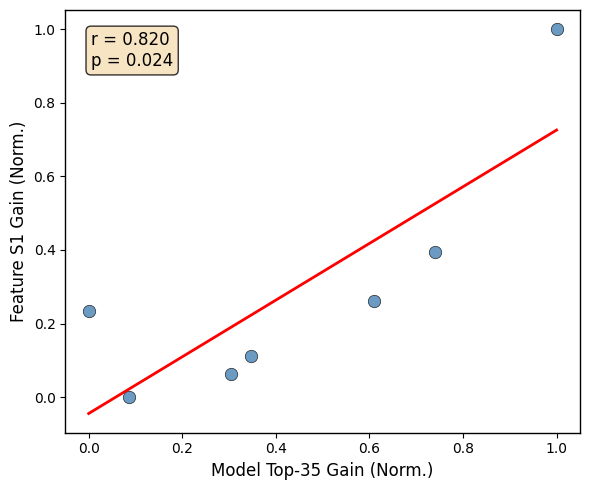

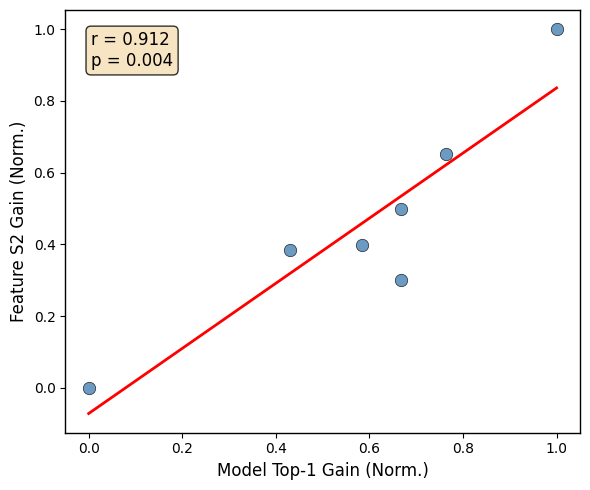

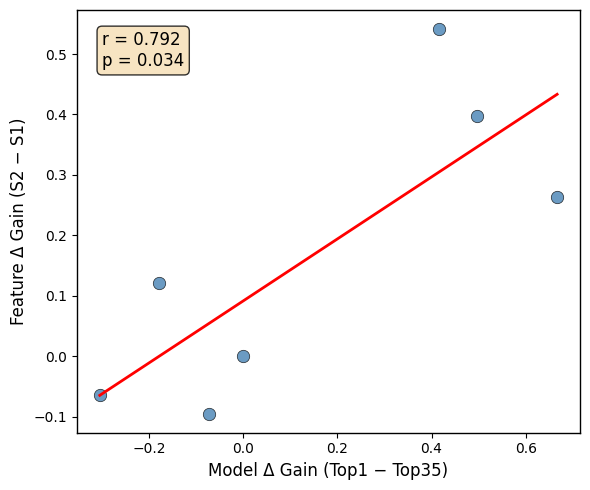

In [11]:
def plot_correlation(X, Y, title, xlabel="Model Gain (Normalized)", ylabel="Feature Gain (Normalized)", save=False):
    corr, p_val = pearsonr(X, Y)
    slope, intercept = np.polyfit(X, Y, 1)
    x_line = np.linspace(X.min(), X.max(), 100)
    y_line = slope * x_line + intercept

    plt.figure(figsize=(6, 5))
    plt.scatter(X, Y, color='steelblue', s=80, alpha=0.8, edgecolor='k', linewidth=0.5)
    plt.plot(x_line, y_line, color='red', linewidth=2)

    # Styling per CNS standards
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
    ax.tick_params(axis='both', colors='black', labelcolor='black')

    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.grid(False)
    plt.tight_layout()

    # Annotate correlation
    text_str = f'r = {corr:.3f}\np = {p_val:.3f}'
    ax.text(0.05, 0.95, text_str, transform=ax.transAxes,
            fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

    plt.savefig(f"{title}.pdf", dpi=300, bbox_inches='tight')
    plt.savefig(f"{title}.png", dpi=300, bbox_inches='tight')
    plt.show()

# Panel 1: Top-35 (Model) vs S1 (Feature)
plot_correlation(
    Top35_Norm, S1_Norm,
    title="Corr_Top35_vs_S1",
    xlabel="Model Top-35 Gain (Norm.)",
    ylabel="Feature S1 Gain (Norm.)"
)

# Panel 2: Top-1 (Model) vs S2 (Feature)
plot_correlation(
    Top1_Norm, S2_Norm,
    title="Corr_Top1_vs_S2",
    xlabel="Model Top-1 Gain (Norm.)",
    ylabel="Feature S2 Gain (Norm.)"
)

# Panel 3: Δ(Top1−Top35) vs Δ(S2−S1)
plot_correlation(
    Delta_Model, Delta_Feature,
    title="Corr_Delta_Top1-Top35_vs_S2-S1",
    xlabel="Model Δ Gain (Top1 − Top35)",
    ylabel="Feature Δ Gain (S2 − S1)"
)
